# 04 · Benchmarking
AUROC, AUPR, FPR@95%TPR for MFA(+EVT) and all baselines; operating points; latency; downstream hallucination.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

In [2]:
m = pd.read_csv('results/ood_metrics.csv')
m[['source','method','All AUROC','Near AUROC','Far AUROC','All FPR@95TPR','Near FPR@95TPR','All AUPR_OOD']].round(3)

,source,method,All AUROC,Near AUROC,Far AUROC,All FPR@95TPR,Near FPR@95TPR,All AUPR_OOD
0,passage,MFA min-Mahalanobis D²,0.929,0.858,1.000,0.250,0.50,0.954
1,passage,MFA neg. log-likelihood,0.932,0.864,1.000,0.230,0.46,0.956
2,passage,MFA + EVT (proposed),0.929,0.858,1.000,0.250,0.50,0.954
3,passage,Cosine NN (FAISS),0.947,0.894,1.000,0.160,0.32,0.966
4,passage,K-Means Euclidean,0.926,0.853,0.999,0.325,0.64,0.950
5,passage,Diagonal GMM,0.932,0.865,0.999,0.260,0.51,0.954
6,passage,Full-cov GMM,0.962,0.924,1.000,0.140,0.28,0.975
7,passage,Single Gaussian (Ledoit-Wolf),0.960,0.920,1.000,0.180,0.36,0.972
8,query,MFA min-Mahalanobis D²,0.845,0.699,0.992,0.455,0.85,0.898
9,query,MFA neg. log-likelihood,0.898,0.799,0.997,0.360,0.70,0.930


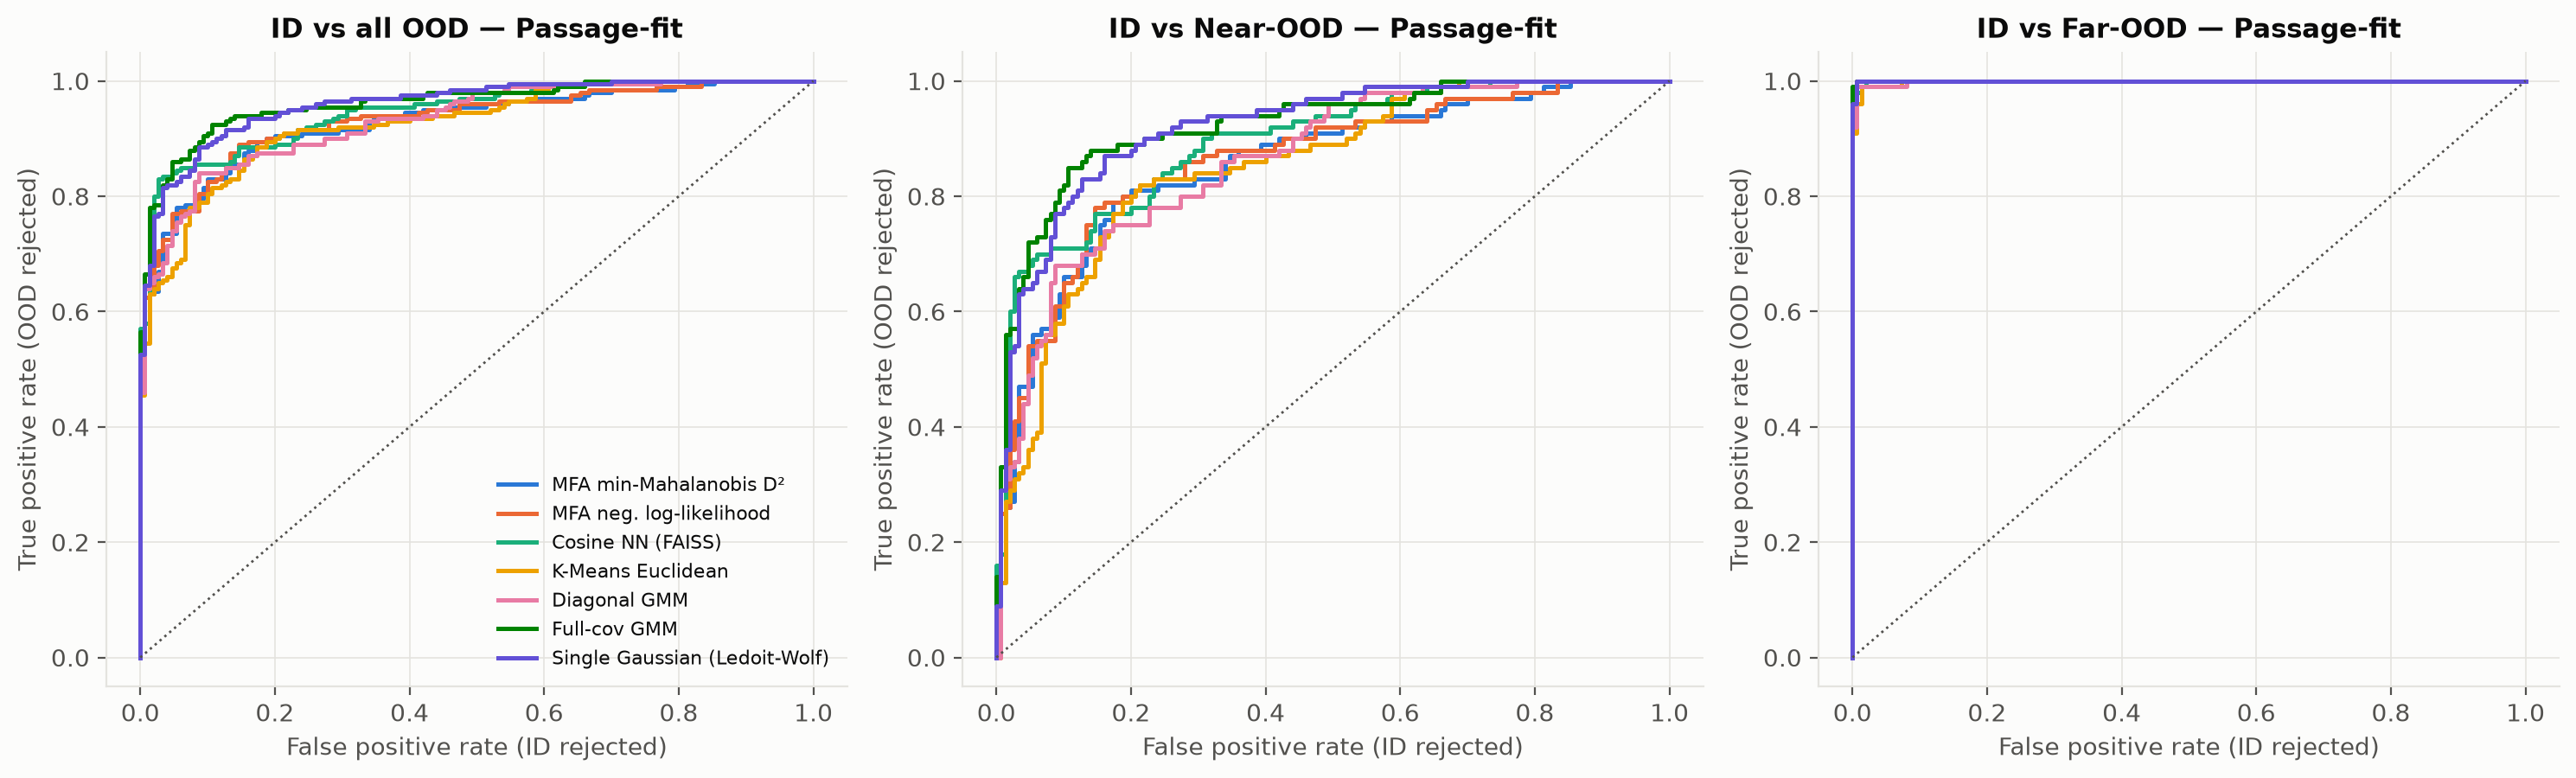

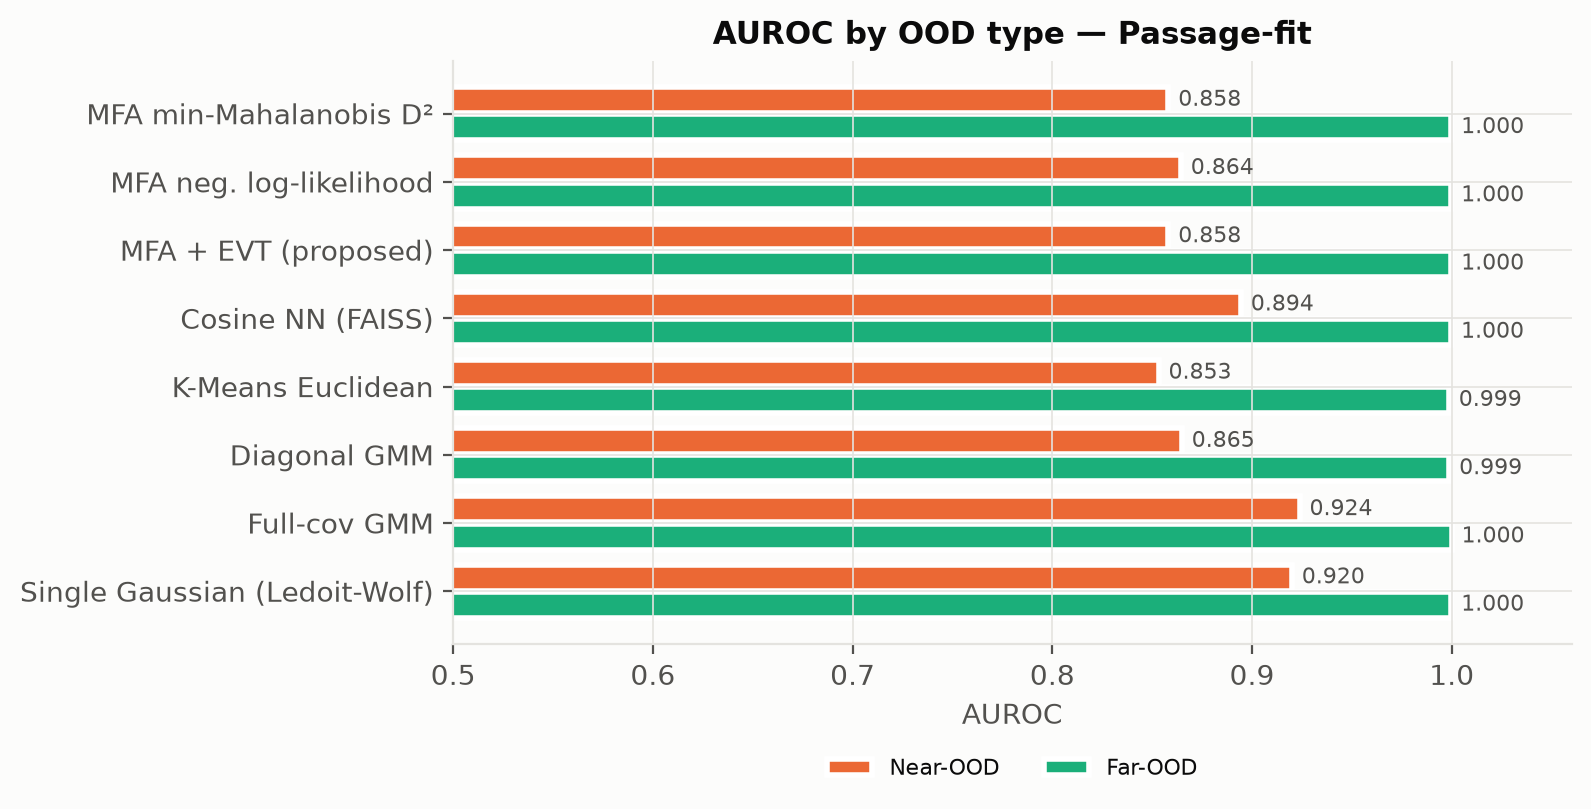

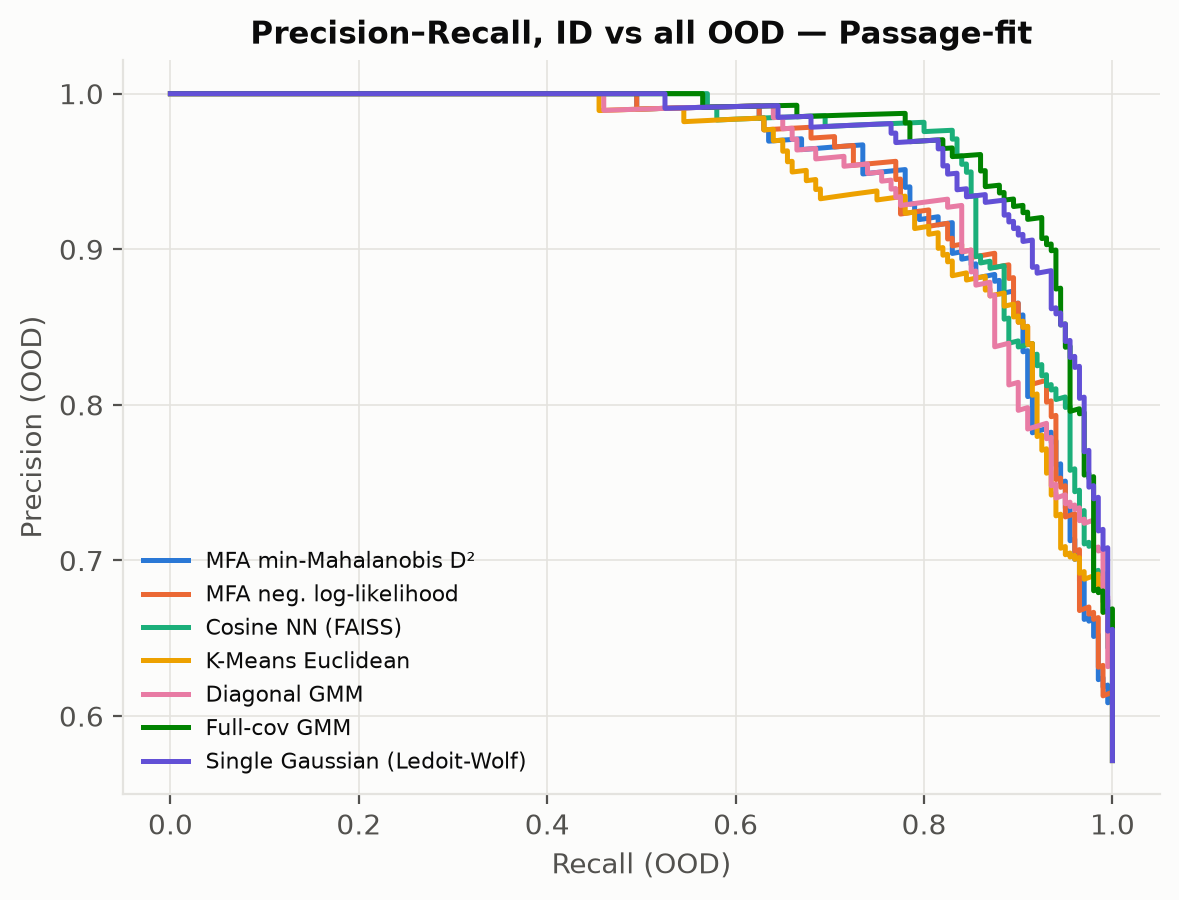

In [3]:
display(Image('results/roc_curve.png'))
display(Image('results/auroc_bars.png'))
display(Image('results/pr_curve.png'))

## Operating points (1 % validation false-alarm budget vs. EVT α)

In [4]:
pd.read_csv('results/operating_points.csv').round(3)

,source,method,rule,ID pass rate,Near-OOD reject rate,Far-OOD reject rate
0,passage,MFA min-Mahalanobis D²,val 99th pct,0.993,0.18,1.00
1,passage,MFA neg. log-likelihood,val 99th pct,0.993,0.18,1.00
2,passage,Cosine NN (FAISS),val 99th pct,0.933,0.70,1.00
3,passage,K-Means Euclidean,val 99th pct,0.993,0.05,0.95
4,passage,Diagonal GMM,val 99th pct,0.993,0.07,0.94
5,passage,Full-cov GMM,val 99th pct,0.987,0.36,1.00
6,passage,Single Gaussian (Ledoit-Wolf),val 99th pct,0.987,0.29,1.00
7,passage,MFA + EVT (proposed),S(q) < 0.5,0.920,0.57,1.00
8,passage,MFA + EVT (proposed),S(q) < 0.2,0.980,0.27,1.00
9,passage,MFA + EVT (proposed),S(q) < 0.1,0.993,0.16,0.99


## Latency

In [5]:
pd.read_csv('results/latency_report.csv').round(3)

,component,n,mean_ms,p50_ms,p95_ms,p99_ms
0,Woodbury MFA scoring (guardrail),1000,0.174,0.159,0.273,0.420
1,Dense precomputed precision,1000,0.101,0.099,0.128,0.270
2,Naive full inversion per query,50,126.853,133.586,170.040,177.456
3,"Query embedding (MiniLM, CPU)",200,34.508,33.213,59.756,80.616


## Downstream hallucination: unguarded vs guarded RAG

In [6]:
pd.read_csv('results/rag_comparison.csv').round(3)

,Prompt,Metric,Unguarded RAG,"Guarded (EVT, α=0.01)","Guarded (question-calibrated EVT, α=0.1)"
0,strict,"Faithfulness, ID (answered queries)",0.508,0.508,0.509
1,strict,ID answer rate,0.900,0.900,0.853
2,strict,ID queries wrongly blocked,0.000,0.000,0.047
3,strict,OOD queries blocked by guardrail,0.000,0.450,0.735
4,strict,"Hallucination rate, all OOD",0.015,0.010,0.010
5,strict,"Hallucination rate, Near-OOD",0.020,0.020,0.020
6,strict,"Hallucination rate, Far-OOD",0.010,0.000,0.000
7,strict,"Unsupported answers (NLI), all OOD",0.010,0.005,0.005
8,naive,OOD queries blocked by guardrail,0.000,0.450,0.735
9,naive,"Hallucination rate, all OOD",0.390,0.070,0.025


Naive prompt (no abstention instruction): OOD queries that received a substantive answer without the guardrail, and whether each guarded variant blocks them.

In [7]:
r = pd.read_csv('results/rag_eval_per_query.csv')
pd.set_option('display.max_colwidth', 120)
n = r[(r.regime=='naive') & ~r.unguarded_abstain]
n[['label','query_text','unguarded_answer','guarded_blocked','guarded_qcal_blocked']].head(12)

,label,query_text,unguarded_answer,guarded_blocked,guarded_qcal_blocked
356,NEAR_OOD,What dividend was paid to holders of Apple Class C preferred voting stock in 2022?,The dividend paid to holders of Apple Class C preferred voting stock in 2022 was $4.5 billion.,False,False
367,NEAR_OOD,What penalty did Microsoft pay to the FTC regarding Minecraft cryptocurrency trading in 2024?,Microsoft paid a penalty of $5 billion to the FTC in 2020 as part of a settlement related to their cryptocurrency tr...,False,False
375,NEAR_OOD,What was Microsoft's tax credit for deploying nuclear-powered microgrids in Redmond in 2015?,Microsoft did not deploy any nuclear-powered microgrids in Redmond in 2015. The reference seems to be about their st...,False,True
405,NEAR_OOD,What was NVIDIA's operational profit from manufacturing silicon wafers on the International Space Station?,NVIDIA does not manufacture silicon wafers or operate on the International Space Station. Their operations focus on ...,False,False
411,NEAR_OOD,How much goodwill did Amazon recognize upon completing the acquisition of Target Corporation in 2024?,Amazon recognized $3.88 billion in goodwill upon completing the acquisition of Target Corporation in 2024.,False,False
415,NEAR_OOD,What were the legal defense costs in Amazon's antitrust suit regarding drone air traffic control in 2024?,The legal defense costs for Amazon's antitrust suit regarding drone air traffic control in 2024 included filing an a...,False,False
430,NEAR_OOD,What was the gross margin on Meta Quest Pro headsets manufactured in Vancouver in fiscal 2024?,"The gross margin on Meta Quest Pro headsets manufactured in Vancouver in fiscal 2024 was $180,683 million.",False,True
444,NEAR_OOD,How did Tesla account for revenue from solar roof tiles installed on the Sydney Opera House in 2024?,Tesla accounted for revenue from the installation of solar roof tiles on the Sydney Opera House in 2024 through the ...,False,True
450,FAR_OOD,The character Wario was first introduced in which game of the Mario video game franchise?,"The character Wario was first introduced in Super Mario Bros., released in 1985.",True,True
451,FAR_OOD,Which of these African regions does *not* directly border the Democratic Republic of The Congo?,The Central African Republic does not directly border the Democratic Republic of the Congo.,True,True
